# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import OSCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [5]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/oscd/",
    "selection": "rgb"
}
dataset = OSCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 24


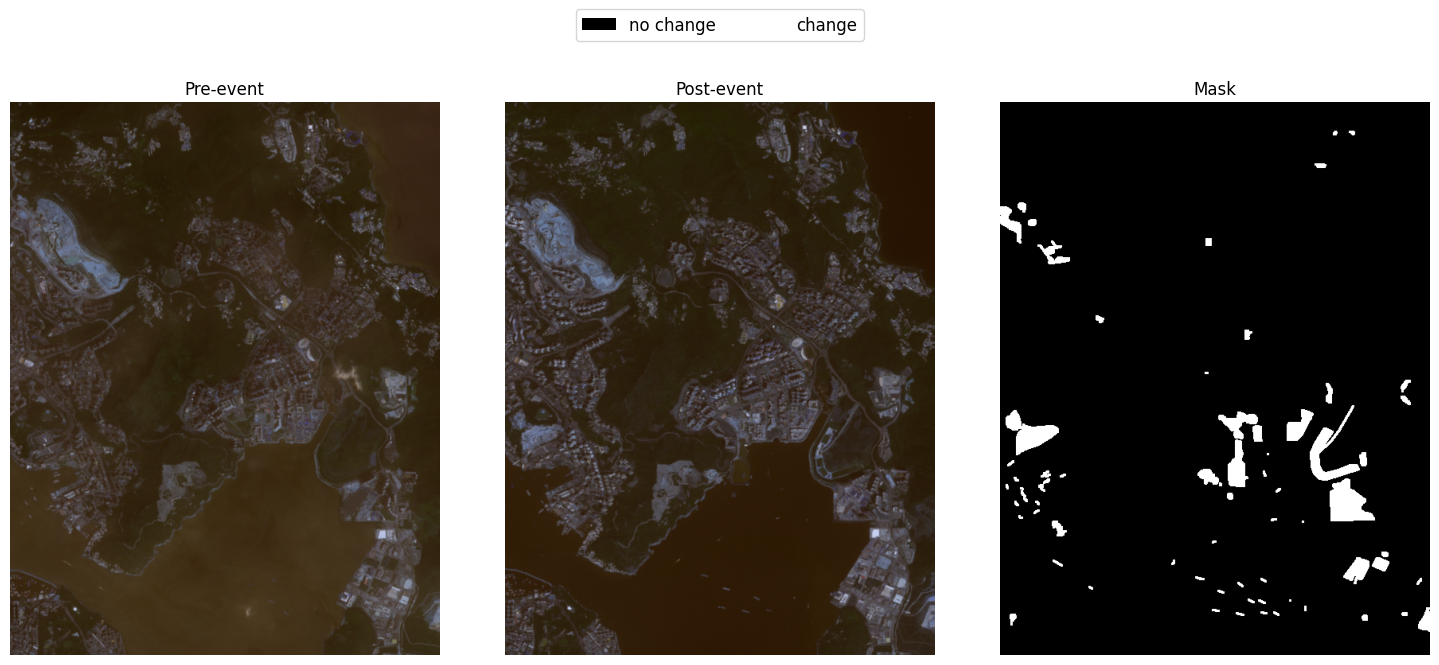

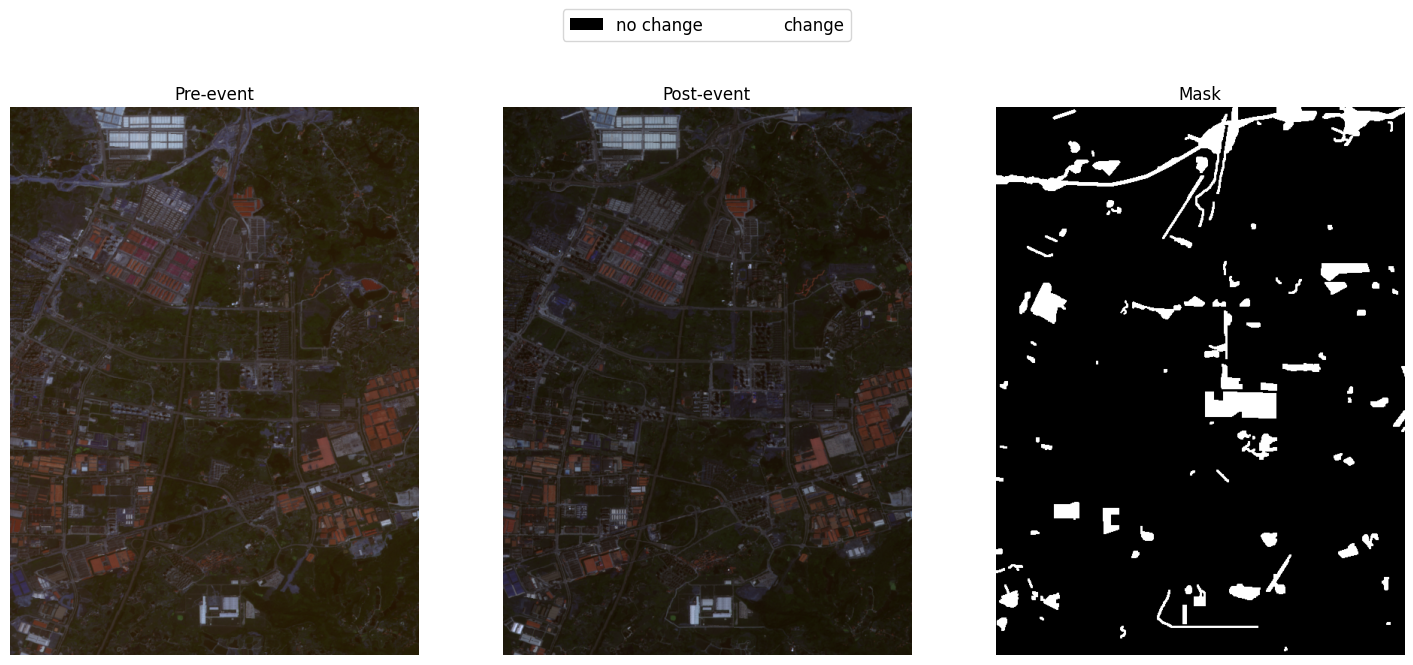

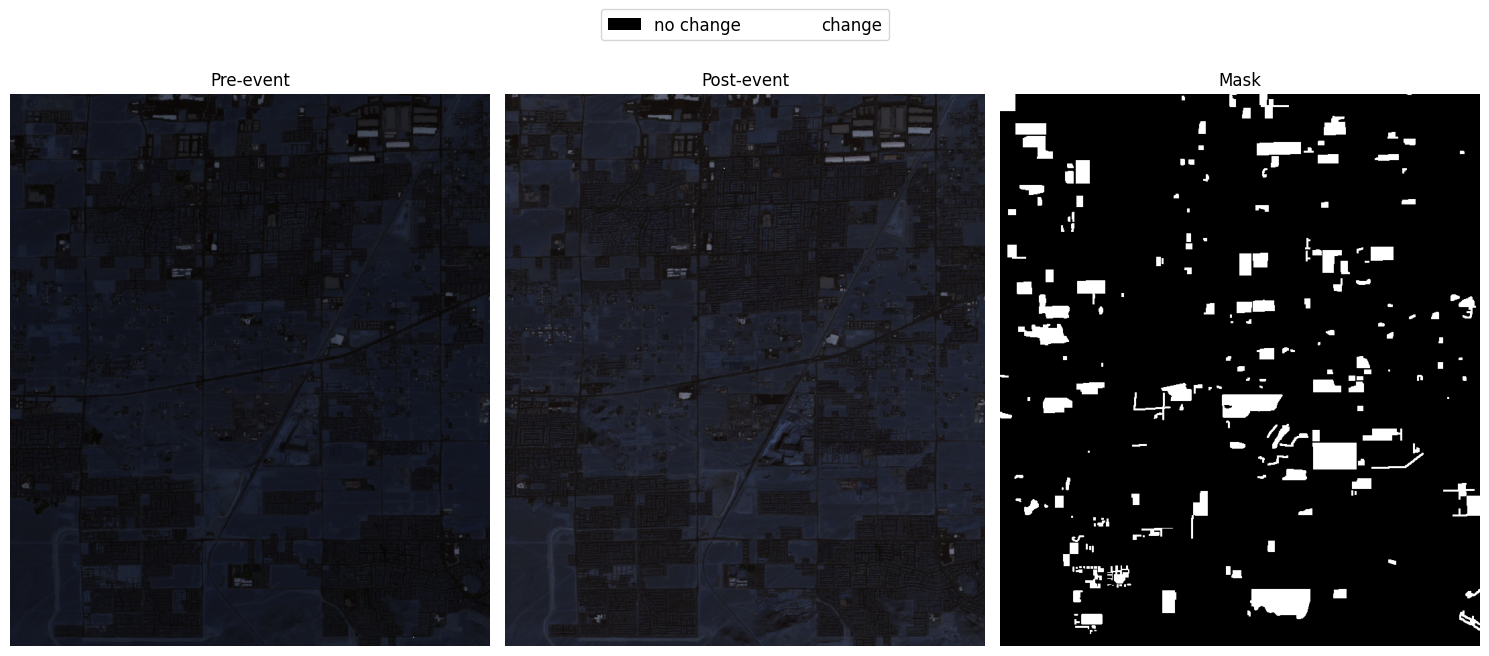

In [6]:
dataset.show_image(1);
dataset.show_image(15);
dataset.show_image(22);

In [67]:
dataset.data_distribution_table()

,Number of pixels
no change,9287247.0
change,308267.0


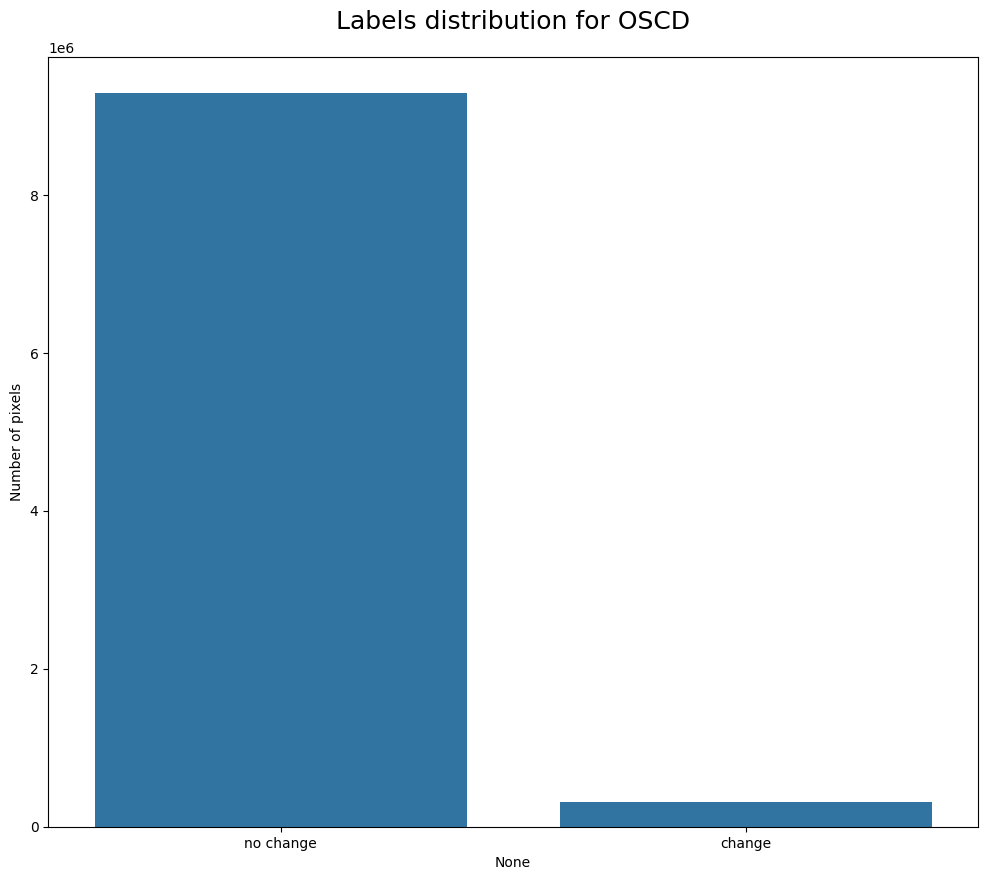

In [68]:
dataset.data_distribution_barchart();

## Load training and test data

In [7]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/oscd/",
    "selection": "rgb",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = OSCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/oscd/",
    "selection": "rgb",
    "mode": "test",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = OSCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(14, 34)

## Create the model

In [9]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/oscd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [10]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-26 12:35:17,003 INFO Starting training.
training: 100%|██████████| 1/1 [00:11<00:00, 11.96s/it]
2026-01-26 12:35:29,010 INFO epoch: 1, loss:  0.29027
testing on train set: 100%|██████████| 1/1 [00:11<00:00, 11.53s/it]
2026-01-26 12:35:41,724 INFO Accuracy:0.5158326285226005, Accuracy per Class:[0.03894043 0.99272483], Precision Micro:0.0, Precision Macro:0.0, Precision Weighted:0.0, Precision per Class:[0. 0.], Recall Micro:0.0, Recall Macro:0.0, Recall Weighted:0.0, Recall per Class:[0. 0.], F1_score Micro:0.0, F1_score Macro:0.0, F1_score Weighted:0.0, F1_score per Class:[0. 0.], IOU:0.0, IOU mean:0.0, IOU per Class:[0. 0.]
training: 100%|██████████| 1/1 [00:11<00:00, 11.76s/it]
2026-01-26 12:35:53,495 INFO epoch: 2, loss:  0.28316
testing on train set: 100%|██████████| 1/1 [00:11<00:00, 11.69s/it]
2026-01-26 12:36:05,227 INFO Accuracy:0.5158326285226005, Accuracy per Class:[0.03894043 0.99272483], Precision Micro:0.0, Precision Macro:0.0, Precision Weighted:0.0, Precision pe